# Predicting 30-day hospital readmission for patients with diabetes

**Question.** At the moment a patient with diabetes is discharged, can we estimate how likely they are to be back in hospital within 30 days, well enough to decide who should get follow-up care?

**Why it matters.** Unplanned readmissions are bad for patients and expensive for health systems. Jencks et al. (NEJM, 2009) found that about one in five US Medicare patients was readmitted within 30 days of discharge. Since 2012 the US Hospital Readmissions Reduction Program has cut payments to hospitals with excess readmissions. Follow-up phone calls, medication reconciliation and early clinic visits reduce readmissions, but they cost staff time, so hospitals need to aim them at the patients most likely to benefit.

**Data.** [Diabetes 130-US Hospitals, 1999 to 2008](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) from the UCI Machine Learning Repository: 101,766 real inpatient encounters from 130 US hospitals, de-identified, first described by Strack et al. (2014).

**What this notebook does**

1. Loads and cleans the raw encounters
2. Explores who gets readmitted
3. Engineers clinically meaningful features
4. Trains a logistic regression baseline and a gradient boosted model
5. Evaluates discrimination, calibration and usefulness for targeting
6. Explains the model and audits it across patient groups
7. Exports the model and summary data for the live dashboard

## 1. Setup

In [1]:
import io
import json
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path("..")
RAW = ROOT / "data" / "raw"
APP = ROOT / "docs" / "data"
RAW.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#77766f"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "axes.axisbelow": True, "font.size": 10,
})

## 2. Load the data

The file is downloaded once from UCI and cached in `data/raw/`. Missing values are coded as `?` in the source, so they are converted to proper missing values on load.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
csv_path = RAW / "diabetic_data.csv"
if not csv_path.exists():
    archive = zipfile.ZipFile(io.BytesIO(requests.get(URL, timeout=120).content))
    archive.extract("diabetic_data.csv", RAW)

raw = pd.read_csv(csv_path, na_values="?", low_memory=False)
print(f"{raw.shape[0]:,} encounters, {raw.shape[1]} columns, {raw['patient_nbr'].nunique():,} unique patients")
raw.head(3)

101,766 encounters, 50 columns, 71,518 unique patients


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


In [3]:
missing = raw.isna().mean().sort_values(ascending=False).head(8).mul(100).round(1)
print("Share of missing values (%), worst columns:")
print(missing.to_string())
print()
print(raw["readmitted"].value_counts(normalize=True).mul(100).round(1).to_string())

Share of missing values (%), worst columns:
weight               96.9
max_glu_serum        94.7
A1Cresult            83.3
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4

readmitted
NO     53.9
>30    34.9
<30    11.2


Three things stand out:

* `weight` is missing for almost every encounter and `payer_code` and `medical_specialty` for 40 to 50 percent, so they are dropped rather than imputed.
* `A1Cresult` and `max_glu_serum` are mostly empty, but here the absence is informative: it means the test was **not ordered**. They are kept, with "Not measured" as its own category.
* The outcome has three levels. The target is readmission **within 30 days** (`<30`), which is the window that regulators and hospitals track.

## 3. Cleaning

Three decisions, each with a reason:

1. **Remove encounters that ended in death or hospice.** Those patients cannot be readmitted, so keeping them would teach the model that very sick patients are "low risk".
2. **Keep one encounter per patient (the first).** Some patients appear dozens of times. Treating their visits as independent rows would leak information between training and test sets and overstate accuracy.
3. **Drop the handful of rows with unknown gender.**

In [4]:
DEATH_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
df = raw[~raw["discharge_disposition_id"].isin(DEATH_OR_HOSPICE)].copy()
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
df = df[df["gender"].isin(["Female", "Male"])]
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
print(f"{len(df):,} patients kept, 30-day readmission rate {df['readmit_30'].mean():.1%}")

69,987 patients kept, 30-day readmission rate 9.0%


## 4. Feature engineering

The raw columns are codes. They are converted into quantities a clinician would recognise:

* **Age** arrives as ten-year brackets and is converted to the bracket midpoint.
* **Diagnoses** are ICD-9 codes with over 700 distinct values. They are grouped into the nine clinical categories used by Strack et al.
* **Admission and discharge** codes are collapsed into a few meaningful groups (for example, discharged home versus transferred to a care facility).
* **Medication** columns (23 drugs) are summarised as the number of diabetes drugs prescribed and the number whose dose changed during the stay.
* **Prior utilisation** (inpatient, emergency and outpatient visits in the previous year) is kept as is. Prior admissions are a well known predictor of future ones.

Race is deliberately **not** given to the model. It is kept aside to audit the model later.

In [5]:
def diagnosis_group(code):
    if pd.isna(code):
        return "Other"
    code = str(code)
    if code.startswith(("V", "E")):
        return "Other"
    value = float(code)
    if 390 <= value <= 459 or value == 785:
        return "Circulatory"
    if 460 <= value <= 519 or value == 786:
        return "Respiratory"
    if 520 <= value <= 579 or value == 787:
        return "Digestive"
    if 250 <= value < 251:
        return "Diabetes"
    if 800 <= value <= 999:
        return "Injury"
    if 710 <= value <= 739:
        return "Musculoskeletal"
    if 580 <= value <= 629 or value == 788:
        return "Genitourinary"
    if 140 <= value <= 239:
        return "Neoplasms"
    return "Other"


def discharge_group(code):
    if code == 1:
        return "Home"
    if code in (6, 8):
        return "Home with care"
    if code in (2, 3, 4, 5, 15, 22, 23, 24, 27, 28, 29, 30):
        return "Care facility"
    return "Other"


def admission_source(code):
    if code == 7:
        return "Emergency room"
    if code in (1, 2, 3):
        return "Referral"
    if code in (4, 5, 6, 10, 22, 25):
        return "Transfer"
    return "Other"


DRUGS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide",
         "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone",
         "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
         "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]

feat = pd.DataFrame(index=df.index)
feat["age"] = df["age"].str.extract(r"\[(\d+)-")[0].astype(int) + 5
feat["female"] = (df["gender"] == "Female").astype(int)
feat["time_in_hospital"] = df["time_in_hospital"]
feat["num_lab_procedures"] = df["num_lab_procedures"]
feat["num_procedures"] = df["num_procedures"]
feat["num_medications"] = df["num_medications"]
feat["number_diagnoses"] = df["number_diagnoses"]
feat["prior_inpatient"] = df["number_inpatient"]
feat["prior_emergency"] = df["number_emergency"]
feat["prior_outpatient"] = df["number_outpatient"]
feat["diabetes_drugs"] = (df[DRUGS] != "No").sum(axis=1)
feat["dose_changes"] = df[DRUGS].isin(["Up", "Down"]).sum(axis=1)
feat["on_diabetes_medication"] = (df["diabetesMed"] == "Yes").astype(int)

cats = pd.DataFrame(index=df.index)
cats["admission_type"] = df["admission_type_id"].map({1: "Emergency", 2: "Urgent", 3: "Elective"}).fillna("Other")
cats["admission_source"] = df["admission_source_id"].map(admission_source)
cats["discharge"] = df["discharge_disposition_id"].map(discharge_group)
cats["primary_diagnosis"] = df["diag_1"].map(diagnosis_group)
cats["a1c"] = df["A1Cresult"].map({"Norm": "Normal", ">7": "7 to 8", ">8": "Above 8"}).fillna("Not measured")
cats["insulin"] = df["insulin"].map({"No": "None", "Steady": "Steady", "Up": "Increased", "Down": "Decreased"})

NUMERIC = list(feat.columns)
CATEGORICAL = list(cats.columns)
onehot = pd.get_dummies(cats, prefix_sep="__").astype(int)
onehot.columns = [c.replace(" ", "_") for c in onehot.columns]
X = pd.concat([feat, onehot], axis=1)
y = df["readmit_30"]
audit = df[["race", "gender"]].assign(age_band=pd.cut(feat["age"], [0, 50, 70, 100], labels=["Under 50", "50 to 69", "70 and over"]))
print(X.shape[1], "model features")

42 model features


## 5. Exploratory analysis

Before modelling, look at how the readmission rate moves with a few variables. Each bar is the share of patients in that group who were readmitted within 30 days. The dashed line is the overall rate.

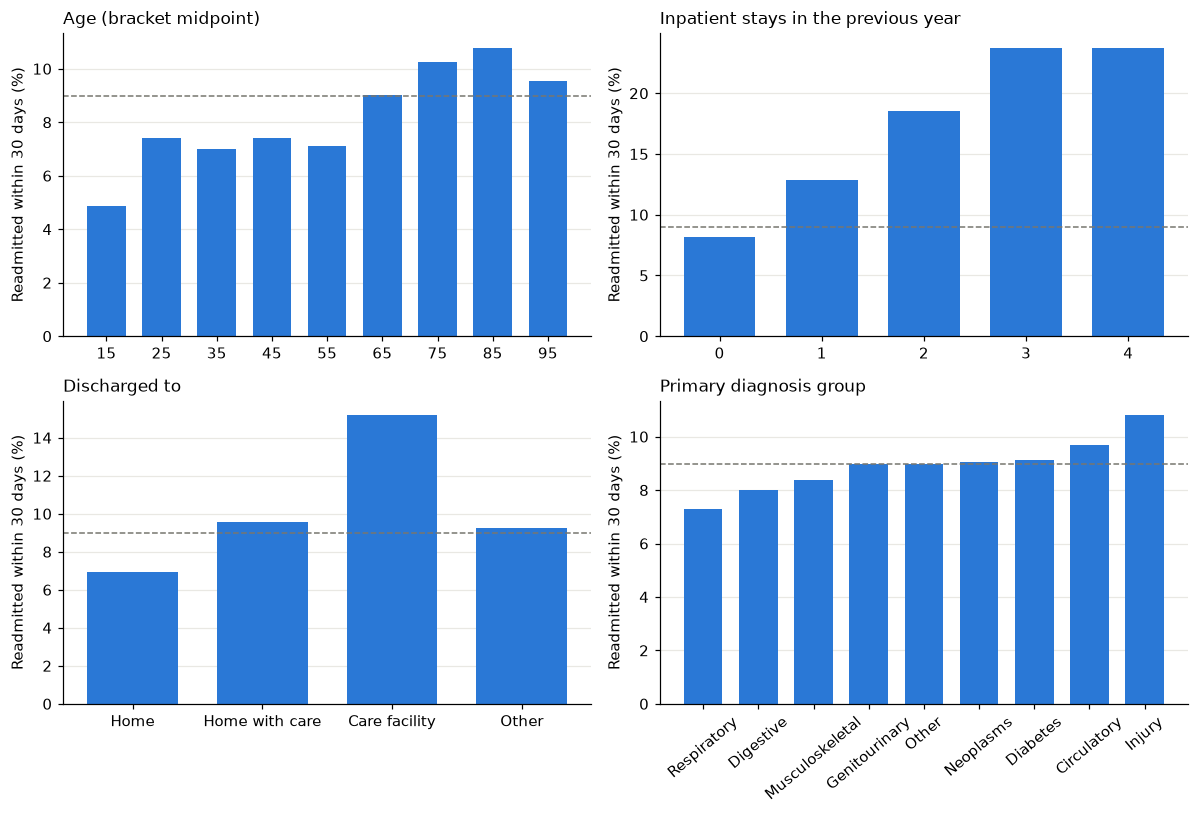

In [6]:
base_rate = y.mean()
explore = pd.concat([feat, cats, y], axis=1)


def rate_by(column, order=None, min_n=200):
    table = explore.groupby(column)["readmit_30"].agg(rate="mean", patients="size")
    table = table[table["patients"] >= min_n]
    return table.loc[order] if order else table


fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
panels = [
    ("age", "Age (bracket midpoint)", None),
    ("prior_inpatient", "Inpatient stays in the previous year", None),
    ("discharge", "Discharged to", ["Home", "Home with care", "Care facility", "Other"]),
    ("primary_diagnosis", "Primary diagnosis group", None),
]
for ax, (column, title, order) in zip(axes.ravel(), panels):
    table = rate_by(column, order)
    if column == "primary_diagnosis":
        table = table.sort_values("rate")
    ax.bar(table.index.astype(str), table["rate"] * 100, color=BLUE, width=0.7)
    ax.axhline(base_rate * 100, color=GREY, ls="--", lw=1)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel("Readmitted within 30 days (%)")
    ax.grid(axis="x", visible=False)
    if column == "primary_diagnosis":
        ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

**What the charts say**

* Risk climbs steadily with age up to the eighties.
* Previous inpatient stays are the clearest signal: patients with one or more stays in the past year are readmitted far more often than those with none.
* Patients sent to a care facility or home with nursing support come back more often than those discharged straight home. Discharge destination is a proxy for frailty.
* Differences between diagnosis groups are real but smaller.

In [7]:
tested = explore.assign(a1c_tested=np.where(explore["a1c"] == "Not measured", "A1C not measured", "A1C measured"))
print(tested.groupby("a1c_tested")["readmit_30"].agg(rate="mean", patients="size").round(4).to_string())

                    rate  patients
a1c_tested                        
A1C measured      0.0840     12846
A1C not measured  0.0911     57141


## 6. Train, validation and test split

60 percent of patients are used for training, 20 percent for tuning and early stopping, and 20 percent are held out and only touched once, for the final evaluation. Splits are stratified so each has the same readmission rate.

In [8]:
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED)
for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11}{len(part):>7,} patients   readmission rate {part.mean():.2%}")

train       41,992 patients   readmission rate 8.98%
validation  13,997 patients   readmission rate 8.98%
test        13,998 patients   readmission rate 8.98%


## 7. Models

**Baseline: logistic regression.** Simple, transparent, and the standard in clinical risk scores. Any more complex model has to beat it to be worth using.

**Gradient boosted trees (XGBoost).** Can capture non-linear effects and interactions, for example that a long stay matters more for an older patient. Shallow trees, a low learning rate and early stopping on the validation set keep it from overfitting.

Neither model reweights the classes. Reweighting would distort the predicted probabilities, and for this use case calibrated probabilities matter more than a hard yes or no.

In [9]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
logit.fit(X_train, y_train)

gbm = xgb.XGBClassifier(
    n_estimators=600, learning_rate=0.03, max_depth=3, min_child_weight=20,
    subsample=0.8, colsample_bytree=0.7, reg_lambda=5.0,
    eval_metric="logloss", early_stopping_rounds=50, random_state=SEED, n_jobs=4,
)
gbm.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Trees kept after early stopping:", gbm.best_iteration + 1)

p_logit = logit.predict_proba(X_test)[:, 1]
p_gbm = gbm.predict_proba(X_test)[:, 1]

Trees kept after early stopping: 386


## 8. Evaluation on the held-out test set

Three questions, three metrics:

* **Can it rank patients?** Area under the ROC curve (AUROC). 0.5 is chance, 1.0 is perfect.
* **Does it find the rare positives?** Average precision (area under the precision-recall curve). The baseline for this is the readmission rate itself.
* **Are the probabilities honest?** Brier score (lower is better) and a calibration plot.

In [10]:
def bootstrap_auc(y_true, p, n=300, seed=SEED):
    rng = np.random.default_rng(seed)
    y_arr, p_arr = np.asarray(y_true), np.asarray(p)
    stats = []
    for _ in range(n):
        idx = rng.integers(0, len(y_arr), len(y_arr))
        if y_arr[idx].min() == y_arr[idx].max():
            continue
        stats.append(roc_auc_score(y_arr[idx], p_arr[idx]))
    return np.percentile(stats, [2.5, 97.5])


rows = []
for name, p in [("Logistic regression", p_logit), ("Gradient boosting", p_gbm)]:
    lo, hi = bootstrap_auc(y_test, p)
    rows.append({"model": name, "AUROC": roc_auc_score(y_test, p), "AUROC 95% low": lo, "AUROC 95% high": hi,
                 "Average precision": average_precision_score(y_test, p), "Brier score": brier_score_loss(y_test, p)})
metrics = pd.DataFrame(rows).set_index("model")
print("Test readmission rate (average precision of a random ranking):", round(y_test.mean(), 4))
metrics.round(4)

Test readmission rate (average precision of a random ranking): 0.0898


,AUROC,AUROC 95% low,AUROC 95% high,Average precision,Brier score
model,,,,,
Logistic regression,0.6340,0.6194,0.6487,0.1515,0.0801
Gradient boosting,0.6392,0.6246,0.6537,0.1559,0.0798


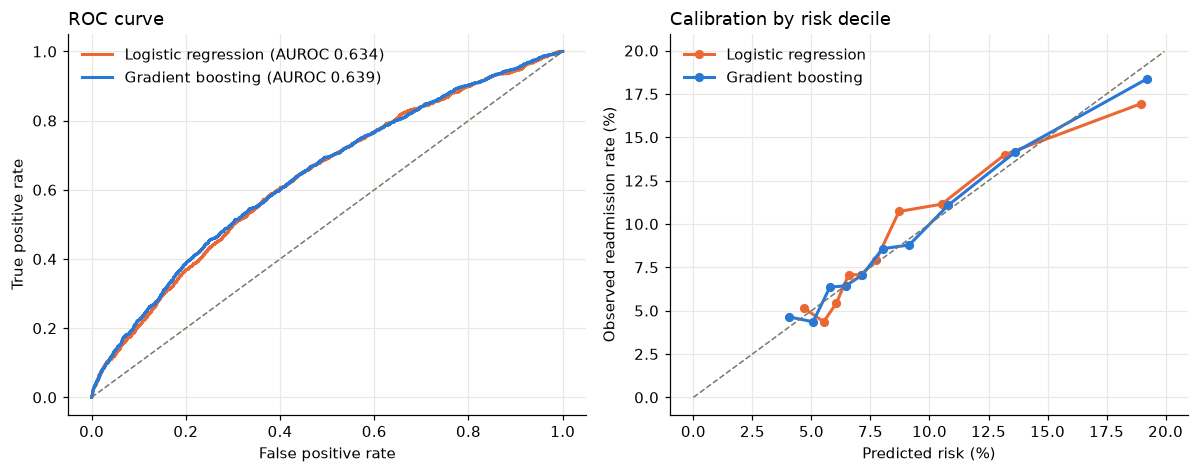

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for name, p, color in [("Logistic regression", p_logit, ORANGE), ("Gradient boosting", p_gbm, BLUE)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUROC {roc_auc_score(y_test, p):.3f})")
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred * 100, frac * 100, "o-", color=color, lw=2, ms=5, label=name)
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
axes[0].set_title("ROC curve", loc="left")
axes[0].legend(frameon=False)
limit = max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])
axes[1].plot([0, limit], [0, limit], color=GREY, ls="--", lw=1)
axes[1].set(xlabel="Predicted risk (%)", ylabel="Observed readmission rate (%)")
axes[1].set_title("Calibration by risk decile", loc="left")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Reading the results honestly.** An AUROC in the mid 0.60s is modest, and it is in line with the published literature: readmission is hard to predict from administrative data, and widely used clinical scores such as LACE and HOSPITAL typically report AUROC between 0.60 and 0.72. Much of what drives readmission (social support, housing, adherence, the quality of the discharge conversation) is simply not in the data.

The boosted model is only slightly ahead of logistic regression, which says most of the signal is additive. What makes the model useful is not the headline number but the next two checks: its probabilities track reality (points close to the diagonal), and it concentrates risk well enough to target scarce follow-up capacity.

## 9. Is it useful? Targeting follow-up care

A hospital cannot give intensive follow-up to everyone. Rank test patients by predicted risk, split them into ten equal groups, and see how readmissions are distributed.

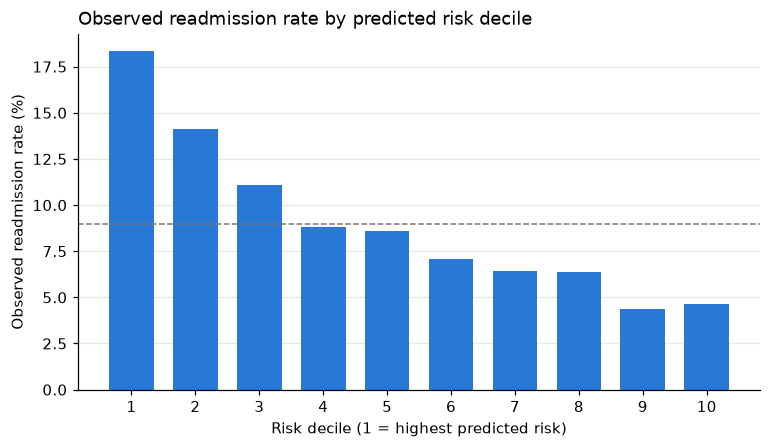

,patients,readmitted,rate,mean_predicted,share_of_all_readmissions,cumulative_share,lift
decile,,,,,,,
1,1400,257,0.184,0.192,0.204,0.204,2.044
2,1400,198,0.141,0.136,0.158,0.362,1.575
3,1400,155,0.111,0.108,0.123,0.485,1.233
4,1399,123,0.088,0.091,0.098,0.583,0.979
5,1400,120,0.086,0.080,0.095,0.679,0.955
6,1400,99,0.071,0.072,0.079,0.757,0.787
7,1399,90,0.064,0.065,0.072,0.829,0.716
8,1400,89,0.064,0.058,0.071,0.900,0.708
9,1400,61,0.044,0.051,0.049,0.948,0.485


In [12]:
test = pd.DataFrame({"y": y_test.values, "p": p_gbm})
test["decile"] = 10 - pd.qcut(test["p"].rank(method="first"), 10, labels=False)
lift = test.groupby("decile").agg(patients=("y", "size"), readmitted=("y", "sum"), rate=("y", "mean"), mean_predicted=("p", "mean"))
lift["share_of_all_readmissions"] = lift["readmitted"] / lift["readmitted"].sum()
lift["cumulative_share"] = lift["share_of_all_readmissions"].cumsum()
lift["lift"] = lift["rate"] / test["y"].mean()

fig, ax = plt.subplots()
ax.bar(lift.index.astype(str), lift["rate"] * 100, color=BLUE, width=0.7)
ax.axhline(test["y"].mean() * 100, color=GREY, ls="--", lw=1)
ax.set(xlabel="Risk decile (1 = highest predicted risk)", ylabel="Observed readmission rate (%)")
ax.set_title("Observed readmission rate by predicted risk decile", loc="left")
ax.grid(axis="x", visible=False)
plt.show()
lift.round(3)

### A simple cost model

Suppose a transitional care programme (nurse phone call within 48 hours, medication review, clinic appointment within a week) costs a fixed amount per patient and prevents a share of the readmissions among the patients who receive it. The numbers below are **assumptions for illustration**, chosen to be in the range reported in the literature, and they can be changed in the dashboard:

* cost of the programme per patient: 300 US dollars
* cost of one readmission: 15,000 US dollars (AHRQ reports an average of about 15,200 dollars in 2018)
* share of readmissions prevented among enrolled patients: 20 percent

The question is how many patients to enrol, working down from the highest risk.

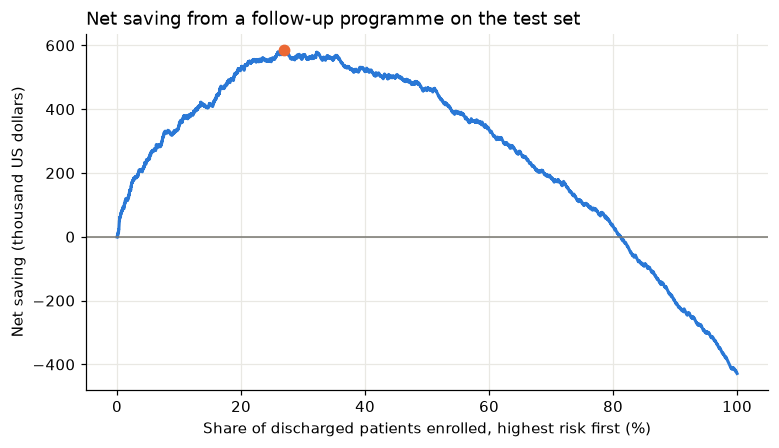

Best policy: enrol the top 27% of patients (risk above 10.4%)
Net saving at that point: $585,300 across 13,998 test patients
Net saving if everyone is enrolled: $-428,400


In [13]:
COST_PROGRAMME, COST_READMISSION, EFFECT = 300, 15_000, 0.20
ranked = test.sort_values("p", ascending=False).reset_index(drop=True)
ranked["enrolled"] = np.arange(1, len(ranked) + 1)
ranked["net_saving"] = ranked["y"].cumsum() * EFFECT * COST_READMISSION - ranked["enrolled"] * COST_PROGRAMME
best = ranked.loc[ranked["net_saving"].idxmax()]
everyone = ranked["net_saving"].iloc[-1]

fig, ax = plt.subplots()
ax.plot(ranked["enrolled"] / len(ranked) * 100, ranked["net_saving"] / 1000, color=BLUE, lw=2)
ax.axhline(0, color=GREY, lw=1)
ax.scatter([best["enrolled"] / len(ranked) * 100], [best["net_saving"] / 1000], color=ORANGE, zorder=3, s=45)
ax.set(xlabel="Share of discharged patients enrolled, highest risk first (%)", ylabel="Net saving (thousand US dollars)")
ax.set_title("Net saving from a follow-up programme on the test set", loc="left")
plt.show()
print(f"Best policy: enrol the top {best['enrolled'] / len(ranked):.0%} of patients (risk above {best['p']:.1%})")
print(f"Net saving at that point: ${best['net_saving']:,.0f} across {len(ranked):,} test patients")
print(f"Net saving if everyone is enrolled: ${everyone:,.0f}")

Under these assumptions, targeting by model score beats both doing nothing and enrolling everyone. The exact optimum depends on the cost and effect assumptions, which is why the dashboard lets a user move them.

## 10. What drives the predictions?

SHAP values split each prediction into contributions from each feature. XGBoost computes them exactly for tree models. The bar chart shows the average absolute contribution of each feature across test patients, in log-odds units, so longer bars mean more influence.

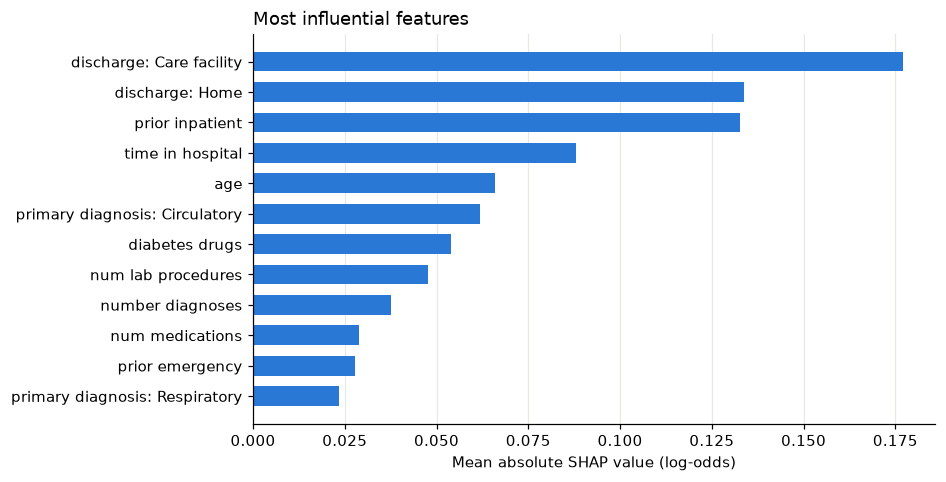

In [14]:
contrib = gbm.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=X.columns).sort_values(ascending=False)
top = importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([name.replace("__", ": ").replace("_", " ") for name in top.index], top.values, color=BLUE, height=0.65)
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_title("Most influential features", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

The ranking matches clinical intuition: where the patient is discharged to, how often they were in hospital in the previous year, their age, and the length and intensity of the stay. That agreement with domain knowledge is a useful sanity check on the model.

## 11. Does the model work equally well for different groups?

A risk model that is accurate on average can still be systematically wrong for a subgroup, and that could direct care away from people who need it. For each group, compare the average predicted risk with the observed rate (calibration) and the AUROC (ranking quality). Race was not an input to the model.

In [15]:
audit_test = audit.loc[X_test.index].assign(y=y_test.values, p=p_gbm)
rows = []
for column in ["gender", "age_band", "race"]:
    for level, group in audit_test.groupby(column, observed=True):
        if len(group) < 300 or group["y"].nunique() < 2:
            continue
        rows.append({"attribute": column, "group": str(level), "patients": len(group), "observed": group["y"].mean(),
                     "predicted": group["p"].mean(), "auroc": roc_auc_score(group["y"], group["p"])})
fairness = pd.DataFrame(rows)
fairness.round(3)

,attribute,group,patients,observed,predicted,auroc
0,gender,Female,7496,0.091,0.091,0.634
1,gender,Male,6502,0.089,0.088,0.645
2,age_band,Under 50,2255,0.074,0.068,0.616
3,age_band,50 to 69,5563,0.082,0.083,0.628
4,age_band,70 and over,6180,0.103,0.103,0.641
5,race,AfricanAmerican,2547,0.090,0.083,0.652
6,race,Caucasian,10430,0.090,0.091,0.630
7,race,Hispanic,318,0.101,0.084,0.683


By gender and age band, predicted and observed rates agree closely. By race, the model slightly under-predicts for African American patients (by under one percentage point) and for Hispanic patients (by about two points, though that group has only a few hundred test patients, so the estimate is noisy). Ranking quality (AUROC) is similar across groups. The gaps are small, but they are the kind of thing that should be monitored and corrected with group-wise recalibration if they persist. Before deployment this audit should be repeated on local data, since the hospitals and years in this dataset will not match any particular hospital today.

## 12. Export for the live dashboard

The dashboard runs the model in the browser, with no server. The trees are written out as plain JSON and the page walks them in JavaScript. To be sure the exported model is the same model, it is re-scored here in pure Python from the exported JSON and compared with XGBoost's own predictions.

In [16]:
def export_trees(model, columns, sample):
    booster = model.get_booster()[: model.best_iteration + 1]
    index = {name: i for i, name in enumerate(columns)}
    trees = []
    for dump in booster.get_dump(dump_format="json"):
        nodes = {}
        stack = [json.loads(dump)]
        while stack:
            node = stack.pop()
            nodes[node["nodeid"]] = node
            stack.extend(node.get("children", []))
        size = max(nodes) + 1
        tree = {"f": [-1] * size, "t": [0] * size, "y": [0] * size, "n": [0] * size, "m": [0] * size, "v": [0] * size}
        for i, node in nodes.items():
            if "leaf" in node:
                tree["v"][i] = round(node["leaf"], 6)
            else:
                tree["f"][i] = index[node["split"]]
                tree["t"][i] = float(np.float32(node["split_condition"]))
                tree["y"][i], tree["n"][i], tree["m"][i] = node["yes"], node["no"], node["missing"]
        trees.append(tree)

    def raw_sum(row):
        total = 0.0
        for tree in trees:
            i = 0
            while tree["f"][i] != -1:
                value = row[tree["f"][i]]
                i = tree["m"][i] if np.isnan(value) else (tree["y"][i] if value < tree["t"][i] else tree["n"][i])
            total += tree["v"][i]
        return total

    values = sample.to_numpy(dtype=np.float32).astype(float)
    sums = np.array([raw_sum(row) for row in values])
    margins = booster.predict(xgb.DMatrix(sample), output_margin=True)
    base = float(np.mean(margins - sums))
    assert np.max(np.abs(sums + base - margins)) < 1e-4, "exported trees do not reproduce the model"
    return {"features": list(columns), "base": round(base, 6), "trees": trees}


exported = export_trees(gbm, X.columns, X_test.head(500))
exported["objective"] = "logistic"
print("Exported", len(exported["trees"]), "trees. Predictions match XGBoost on 500 test patients.")

Exported 386 trees. Predictions match XGBoost on 500 test patients.


In [17]:
def records(frame):
    return json.loads(frame.reset_index().to_json(orient="records"))


schema = {
    "numeric": [{"name": c, "min": int(feat[c].min()), "max": int(feat[c].quantile(0.999)), "default": int(feat[c].median())}
                for c in NUMERIC],
    "categorical": [{"name": c, "levels": sorted(cats[c].unique()), "default": cats[c].mode()[0]} for c in CATEGORICAL],
}
frac, mean_pred = calibration_curve(y_test, p_gbm, n_bins=10, strategy="quantile")
fpr, tpr, _ = roc_curve(y_test, p_gbm)
keep = np.linspace(0, len(fpr) - 1, 120).astype(int)
summary = {
    "patients": int(len(df)),
    "encounters_raw": int(len(raw)),
    "base_rate": float(base_rate),
    "test_patients": int(len(y_test)),
    "metrics": json.loads(metrics.reset_index().to_json(orient="records")),
    "rate_by_age": records(rate_by("age")),
    "rate_by_prior_inpatient": records(rate_by("prior_inpatient")),
    "rate_by_discharge": records(rate_by("discharge")),
    "rate_by_diagnosis": records(rate_by("primary_diagnosis").sort_values("rate")),
    "calibration": {"predicted": mean_pred.tolist(), "observed": frac.tolist()},
    "roc": {"fpr": fpr[keep].tolist(), "tpr": tpr[keep].tolist()},
    "lift": records(lift),
    "importance": [{"feature": k.replace("__", ": ").replace("_", " "), "value": float(v)} for k, v in importance.head(12).items()],
    "fairness": json.loads(fairness.to_json(orient="records")),
    "risk_quantiles": np.quantile(p_gbm, np.linspace(0, 1, 101)).tolist(),
    "ranked_outcomes": ranked["y"].astype(int).tolist(),
    "schema": schema,
}
(APP / "model.json").write_text(json.dumps(exported, separators=(",", ":")))
(APP / "summary.json").write_text(json.dumps(summary, separators=(",", ":")))
print("model.json", round((APP / "model.json").stat().st_size / 1024), "KB")
print("summary.json", round((APP / "summary.json").stat().st_size / 1024), "KB")

model.json 105 KB
summary.json 41 KB


## 13. Conclusions

* A model built only from data available at discharge can rank patients by 30-day readmission risk with an AUROC in the mid 0.60s. That is comparable to clinical scores in routine use, and its probabilities are well calibrated.
* The strongest signals are previous hospital use, discharge destination, age, and the length and intensity of the stay.
* Used for targeting, the model concentrates readmissions: the highest risk tenth of patients is readmitted at roughly twice the average rate. Under plausible cost assumptions, a targeted follow-up programme saves more than either treating everyone or no one.
* The model ranks patients about equally well across gender, age and race groups, with a small under-prediction for African American and Hispanic patients that would need monitoring.

**Limitations**

* The data covers 1999 to 2008. Care pathways and drugs have changed, so the model would need retraining on recent local data before any real use.
* Only the first encounter per patient is modelled, and readmissions to hospitals outside the 130 in the dataset are not observed.
* Important drivers such as social support, housing and health literacy are not recorded.
* The cost model assumes the programme works equally well at every risk level, which is unlikely to hold exactly. Estimating who actually benefits needs a randomised trial or an uplift model.

**Next steps.** Add all encounters with a patient-grouped split and time-since-last-discharge features, test recalibration on a more recent cohort, and compare with the LACE index on the same patients.